# Latihan Preprocessing dan Text Vectorization
Nama: (widia sari handini)  
NIM: (2315015016)

Data: kalimat sederhana tentang pengalaman makan di warung (positif dan negatif).

In [2]:
!pip install -q Sastrawi

## Data

In [1]:
import pandas as pd

positif = [
    "Makanan di warung ini enak sekali!",
    "Saya suka makan nasi goreng.",
    "Pelayanannya ramah dan cepat.",
    "Harga makanannya murah.",
    "Tempat makannya bersih dan nyaman.",
    "Saya sangat senang dengan rasanya.",
    "Es teh di sini segar.",
    "Porsinya banyak dan kenyang.",
    "Pegawainya baik dan sopan.",
    "Saya pasti makan di sini lagi.",
]

negatif = [
    "Makanannya tidak enak.",
    "Pelayanannya lambat sekali.",
    "Harga makanannya terlalu mahal.",
    "Tempat makannya kotor dan panas.",
    "Saya kecewa dengan rasanya.",
    "Nasinya keras dan dingin.",
    "Saya menunggu 1 jam untuk pesanan.",
    "Pegawainya tidak ramah.",
    "Porsinya kecil dan tidak kenyang.",
    "Saya tidak mau makan di sini lagi.",
]

data = pd.DataFrame({
    'teks': positif + negatif,
    'label': ['positif'] * 10 + ['negatif'] * 10
})
data.head()

,teks,label
0,Makanan di warung ini enak sekali!,positif
1,Saya suka makan nasi goreng.,positif
2,Pelayanannya ramah dan cepat.,positif
3,Harga makanannya murah.,positif
4,Tempat makannya bersih dan nyaman.,positif


In [3]:
print('Ukuran data:', data.shape)
print(data.isna().sum())
print(data['label'].value_counts())

Ukuran data: (20, 2)
teks     0
label    0
dtype: int64
label
positif    10
negatif    10
Name: count, dtype: int64


## Case folding dan pembersihan tanda baca

In [4]:
data['huruf_kecil'] = data['teks'].str.lower()
data['bersih'] = data['huruf_kecil'].str.replace(r'[^a-z0-9\s]', ' ', regex=True)
data['bersih'] = data['bersih'].str.replace(r'\s+', ' ', regex=True).str.strip()

data[['teks', 'bersih']].head()

,teks,bersih
0,Makanan di warung ini enak sekali!,makanan di warung ini enak sekali
1,Saya suka makan nasi goreng.,saya suka makan nasi goreng
2,Pelayanannya ramah dan cepat.,pelayanannya ramah dan cepat
3,Harga makanannya murah.,harga makanannya murah
4,Tempat makannya bersih dan nyaman.,tempat makannya bersih dan nyaman


## Tokenisasi

In [5]:
contoh = data.loc[0, 'bersih']
token = contoh.split()
print('Teks :', contoh)
print('Token:', token)

Teks : makanan di warung ini enak sekali
Token: ['makanan', 'di', 'warung', 'ini', 'enak', 'sekali']


## Stopwords

In [6]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)
print('Jumlah token:', len(token), '->', len(token_penting))

['makanan', 'warung', 'enak', 'sekali']
Jumlah token: 6 -> 4


## Stemming

In [7]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['makanan', 'warung', 'enak', 'sekali']
Sesudah: ['makan', 'warung', 'enak', 'sekali']


## Frekuensi kata

[('tidak', 4), ('makan', 3), ('makanannya', 3), ('sini', 3), ('enak', 2), ('sekali', 2), ('pelayanannya', 2), ('ramah', 2), ('harga', 2), ('tempat', 2)]


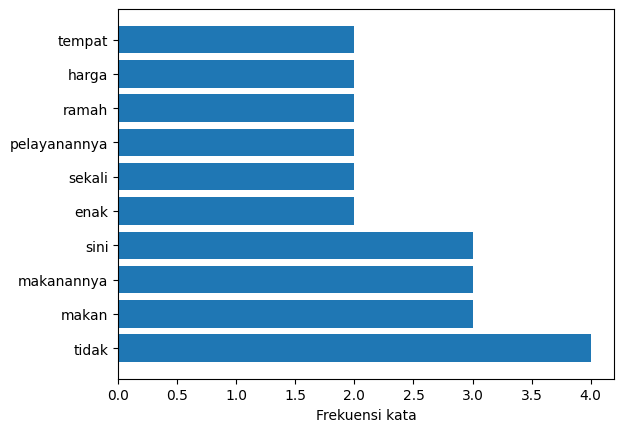

In [8]:
from collections import Counter
import matplotlib.pyplot as plt

semua_kata = ' '.join(data['bersih']).split()
frekuensi = Counter(kata for kata in semua_kata if kata not in stopwords)
print(frekuensi.most_common(10))

kata, jumlah = zip(*frekuensi.most_common(10))
plt.barh(kata, jumlah)
plt.xlabel('Frekuensi kata')
plt.show()

## Bag of Words

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih'].head(5)

count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

pd.DataFrame(matriks_count.toarray(), columns=count.get_feature_names_out())

,bersih,cepat,dan,di,enak,goreng,harga,ini,makan,makanan,...,murah,nasi,nyaman,pelayanannya,ramah,saya,sekali,suka,tempat,warung
0,0,0,0,1,1,0,0,1,0,1,...,0,0,0,0,0,0,1,0,0,1
1,0,0,0,0,0,1,0,0,1,0,...,0,1,0,0,0,1,0,1,0,0
2,0,1,1,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,1,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0


## TF-IDF

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
matriks_tfidf = tfidf.fit_transform(dokumen)

pd.DataFrame(matriks_tfidf.toarray(), columns=tfidf.get_feature_names_out()).round(2)

,bersih,cepat,dan,di,enak,goreng,harga,ini,makan,makanan,...,murah,nasi,nyaman,pelayanannya,ramah,saya,sekali,suka,tempat,warung
0,0.00,0.00,0.00,0.41,0.41,0.00,0.00,0.41,0.00,0.41,...,0.00,0.00,0.00,0.00,0.00,0.00,0.41,0.00,0.00,0.41
1,0.00,0.00,0.00,0.00,0.00,0.45,0.00,0.00,0.45,0.00,...,0.00,0.45,0.00,0.00,0.00,0.45,0.00,0.45,0.00,0.00
2,0.00,0.52,0.42,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.52,0.52,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.58,0.00,0.00,0.00,...,0.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.46,0.00,0.37,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.46,0.00,0.00,0.00,0.00,0.00,0.46,0.00
